<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema4-arvore-decisao/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 4: Classificação de Risco de Crédito Utilizando Árvores de Decisão

Neste trabalho vamos construir uma árvore de decisão para classificar solicitantes de crédito em **bom pagador** e **mau pagador**, usando o *dataset* **Statlog (German Credit Data)**. O fluxo segue o notebook de árvores de decisão da disciplina (`08_Tree.ipynb`), adaptado ao problema: atributos categóricos, classes desbalanceadas, escolha da profundidade por validação cruzada e interpretação das regras.

Inicialmente, vamos importar as bibliotecas:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, recall_score

Realizando algumas configurações nos plots:

In [2]:
plt.rcParams["font.family"] = "Arial"
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams['mathtext.rm'] = "Arial"
plt.rcParams['mathtext.it'] = "Arial:italic"
plt.rcParams['mathtext.bf'] = "Arial:bold"
plt.rcParams['figure.figsize'] = (8, 5)

# Pasta onde as figuras usadas no relatório são salvas
os.makedirs("figuras", exist_ok=True)

## 1. Conjunto de Dados

Vamos usar a versão com rótulos legíveis (`credit-g`), como sugerido no enunciado. O alvo é transformado em 0 (bom pagador) e 1 (mau pagador):

In [3]:
dados = fetch_openml(name="credit-g", version=1, as_frame=True)
X = dados.data.copy()
y = (dados.target == "bad").astype(int)

X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [4]:
print(f"Quantidade de amostras = {X.shape[0]}")
print(f"Quantidade de atributos = {X.shape[1]}")
print("Faltantes (total):", X.isna().sum().sum())
print("Linhas duplicadas:", X.duplicated().sum())

Quantidade de amostras = 1000
Quantidade de atributos = 20
Faltantes (total): 0
Linhas duplicadas: 0


## 2. Tarefa 1: Preparação dos Dados

Identificando quais atributos são numéricos e quais são categóricos:

In [5]:
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = X.select_dtypes(exclude="number").columns.tolist()

print(f"Atributos numéricos ({len(cols_num)}):", cols_num)
print(f"\nAtributos categóricos ({len(cols_cat)}):", cols_cat)

print("\nNúmero de categorias de cada atributo categórico:")
print(X[cols_cat].nunique().sort_values(ascending=False))

Atributos numéricos (7): ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Atributos categóricos (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Número de categorias de cada atributo categórico:
purpose                10
savings_status          5
credit_history          5
employment              5
checking_status         4
personal_status         4
property_magnitude      4
job                     4
other_parties           3
other_payment_plans     3
housing                 3
own_telephone           2
foreign_worker          2
dtype: int64


In [6]:
display(X[cols_num].describe().round(2))

,duration,credit_amount,installment_commitment,residence_since,age,existing_credits,num_dependents
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,2.97,2.84,35.55,1.41,1.16
std,12.06,2822.74,1.12,1.10,11.38,0.58,0.36
min,4.00,250.00,1.00,1.00,19.00,1.00,1.00
25%,12.00,1365.50,2.00,2.00,27.00,1.00,1.00
50%,18.00,2319.50,3.00,3.00,33.00,1.00,1.00
75%,24.00,3972.25,4.00,4.00,42.00,2.00,1.00
max,72.00,18424.00,4.00,4.00,75.00,4.00,2.00


A `sklearn` exige entradas numéricas, então os atributos categóricos precisam ser codificados. A escolha depende do tipo do atributo:

- **Ordinal**: para categorias **com ordem** natural;
- **One-Hot**: para categorias **nominais** (sem ordem).

A maioria dos atributos categóricos é nominal (por exemplo, `purpose`, `personal_status`, `housing`); usar uma codificação ordinal neles criaria uma **ordem falsa** que a árvore interpretaria como informação real. Por isso vamos usar o *one-hot encoding* em todos os atributos categóricos:

In [7]:
oh = OneHotEncoder(sparse_output=False)
X_ohe = oh.fit_transform(X[cols_cat])

df_ohe = pd.DataFrame(X_ohe, columns=oh.get_feature_names_out(cols_cat), index=X.index)
X_enc = pd.concat([X[cols_num], df_ohe], axis=1)

print("Dimensão após o one-hot encoding:", X_enc.shape)

Dimensão após o one-hot encoding: (1000, 61)


Avaliando o balanceamento entre as classes:

In [8]:
print(f"Quantidade de bons pagadores (0) = {np.bincount(y)[0]} ({100 * np.mean(y == 0):.0f}%)")
print(f"Quantidade de maus pagadores (1) = {np.bincount(y)[1]} ({100 * np.mean(y == 1):.0f}%)")

Quantidade de bons pagadores (0) = 700 (70%)
Quantidade de maus pagadores (1) = 300 (30%)


O conjunto é **desbalanceado** (70%/30%). Um classificador que sempre prevê "bom pagador" já acerta 70% das amostras sem identificar nenhum mau pagador, então a acurácia sozinha engana: ela precisa ser comparada com esse valor e acompanhada do *recall* da classe "mau".

## 3. Tarefa 2: Normalização

A árvore de decisão **não** precisa de normalização: cada nó compara **um único atributo** com um limiar ($x_j \leq t$). Uma transformação monotônica do atributo (como a padronização ou o Min-Max) apenas desloca o limiar para o valor transformado, sem mudar a ordem das amostras, os grupos formados nem a impureza calculada. Não há cálculo de distância entre atributos diferentes, como no $k$-NN. Isso é verificado na Seção 5.

## 4. Tarefa 3: Divisão Treino/Teste

Realizando a divisão em treino (80%) e teste (20%), de forma estratificada:

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
        X_enc, y, test_size=0.2, random_state=42, stratify=y
    )

print(f"Treino: {X_train.shape[0]} amostras | proporção de maus = {y_train.mean():.2f}")
print(f"Teste:  {X_test.shape[0]} amostras | proporção de maus = {y_test.mean():.2f}")

Treino: 800 amostras | proporção de maus = 0.30
Teste:  200 amostras | proporção de maus = 0.30


Classificador de referência, que sempre prevê a classe majoritária:

In [10]:
burro = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_burro = burro.predict(X_test)

print(f"Acurácia: {accuracy_score(y_test, y_burro):.3f}  <-- parece razoável")
print(f"Recall (mau pagador): {recall_score(y_test, y_burro):.3f}  <-- não detecta NENHUM mau pagador")

Acurácia: 0.700  <-- parece razoável
Recall (mau pagador): 0.000  <-- não detecta NENHUM mau pagador


## 5. Tarefa 4: Treinamento e Controle de Complexidade

Vamos treinar árvores com diferentes profundidades máximas (2, 3, 5, 7, 10 e sem limite) utilizando validação cruzada de 5 *folds* sobre o treino, primeiro com o critério de Gini e depois com a entropia. A função `cross_validate` com `return_train_score=True` retorna também o desempenho no treino de cada *fold*.

Além da acurácia, registramos o **F1-*score* macro** (média simples do F1 das duas classes). Como visto na aula de métricas, a média macro é a preferida quando há desbalanceamento, porque não deixa a classe majoritária esconder o desempenho na minoritária:

In [11]:
profundidades = [2, 3, 5, 7, 10, None]
linhas = []

for criterio in ["gini", "entropy"]:
    for d in profundidades:
        arvore = DecisionTreeClassifier(criterion=criterio, max_depth=d, random_state=42)
        r = cross_validate(arvore, X_train, y_train, cv=5, scoring=["accuracy", "f1_macro"],
                           return_train_score=True)
        linhas.append((criterio, "sem limite" if d is None else str(d),
                       r["train_accuracy"].mean(), r["test_accuracy"].mean(), r["test_accuracy"].std(),
                       r["train_f1_macro"].mean(), r["test_f1_macro"].mean(), r["test_f1_macro"].std()))
        print(f"{criterio:7s} | max_depth = {str(d):4s} | "
              f"Acurácia treino: {r['train_accuracy'].mean():.4f} | validação: {r['test_accuracy'].mean():.4f} | "
              f"F1 macro validação: {r['test_f1_macro'].mean():.4f} ± {r['test_f1_macro'].std():.4f}")

tabela = pd.DataFrame(linhas, columns=["criterio", "profundidade",
                                       "acc_treino", "acc_validacao", "acc_desvio",
                                       "f1_treino", "f1_validacao", "f1_desvio"])

gini    | max_depth = 2    | Acurácia treino: 0.7075 | validação: 0.7025 | F1 macro validação: 0.5069 ± 0.1165
gini    | max_depth = 3    | Acurácia treino: 0.7378 | validação: 0.6963 | F1 macro validação: 0.6087 ± 0.0742


gini    | max_depth = 5    | Acurácia treino: 0.8187 | validação: 0.6838 | F1 macro validação: 0.6004 ± 0.0368

gini    | max_depth = 7    | Acurácia treino: 0.8841 | validação: 0.6800 | F1 macro validação: 0.6051 ± 0.0193


gini    | max_depth = 10   | Acurácia treino: 0.9597 | validação: 0.6800 | F1 macro validação: 0.6120 ± 0.0177
gini    | max_depth = None | Acurácia treino: 1.0000 | validação: 0.6600 | F1 macro validação: 0.5947 ± 0.0239


entropy | max_depth = 2    | Acurácia treino: 0.7034 | validação: 0.7025 | F1 macro validação: 0.4583 ± 0.0931


entropy | max_depth = 3    | Acurácia treino: 0.7319 | validação: 0.6925 | F1 macro validação: 0.6458 ± 0.0175


entropy | max_depth = 5    | Acurácia treino: 0.8000 | validação: 0.6950 | F1 macro validação: 0.6424 ± 0.0259
entropy | max_depth = 7    | Acurácia treino: 0.8588 | validação: 0.6525 | F1 macro validação: 0.5934 ± 0.0128


entropy | max_depth = 10   | Acurácia treino: 0.9363 | validação: 0.6687 | F1 macro validação: 0.6072 ± 0.0098


entropy | max_depth = None | Acurácia treino: 1.0000 | validação: 0.6687 | F1 macro validação: 0.6142 ± 0.0171


Plotando, em um mesmo gráfico, a métrica média de treino e a de validação em função da profundidade (colunas: critério; linhas: acurácia e F1 macro):

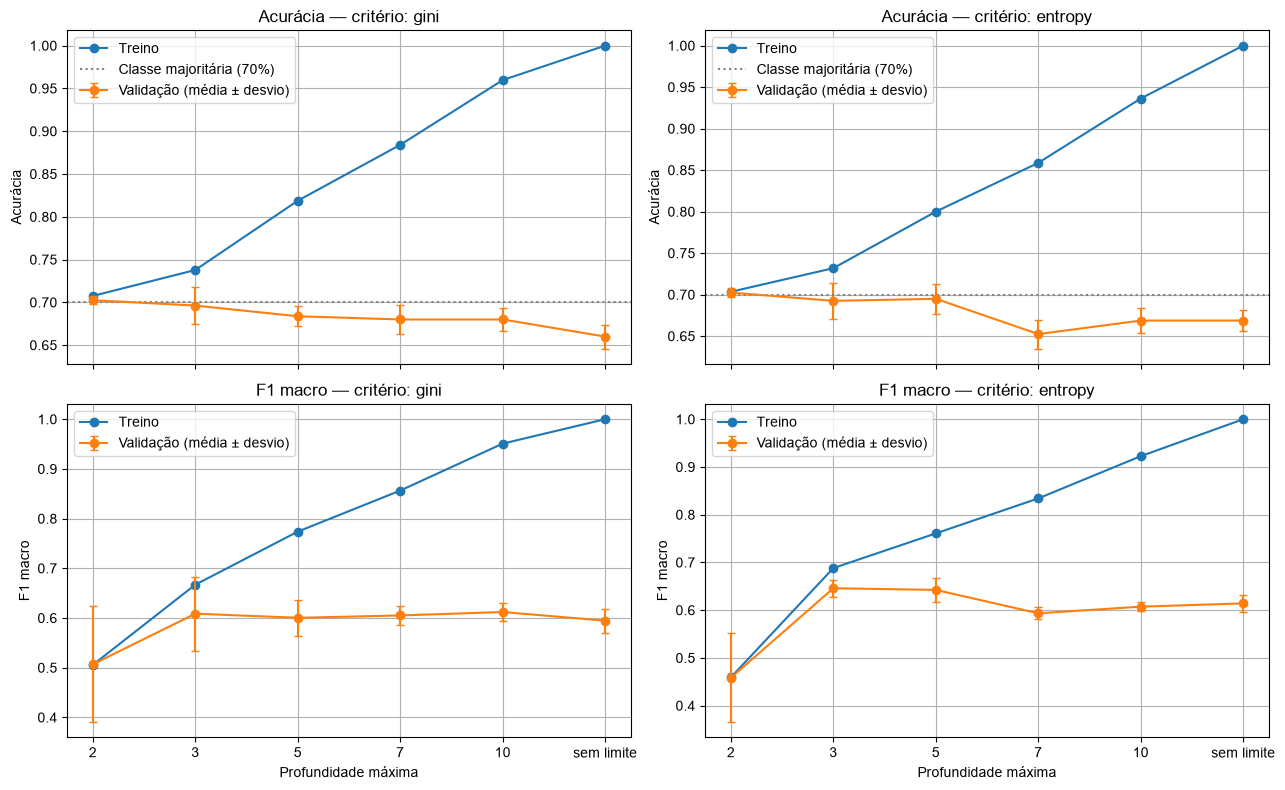

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for j, criterio in enumerate(["gini", "entropy"]):
    t = tabela[tabela["criterio"] == criterio]
    for i, (metrica, nome) in enumerate([("acc", "Acurácia"), ("f1", "F1 macro")]):
        a = ax[i, j]
        a.plot(t["profundidade"], t[f"{metrica}_treino"], marker="o", label="Treino")
        a.errorbar(t["profundidade"], t[f"{metrica}_validacao"], yerr=t[f"{metrica}_desvio"],
                   marker="o", capsize=3, label="Validação (média ± desvio)")
        if metrica == "acc":
            a.axhline(0.70, color="gray", linestyle=":", label="Classe majoritária (70%)")
        a.set_ylabel(nome)
        a.set_title(f"{nome} — critério: {criterio}")
        a.legend()
        a.grid()
for a in ax[1]:
    a.set_xlabel("Profundidade máxima")

plt.tight_layout()
plt.savefig("figuras/curva_profundidade.png", dpi=150, bbox_inches="tight")
plt.show()

Verificando qual seria a melhor profundidade por cada métrica, em cada critério:

In [13]:
for criterio in ["gini", "entropy"]:
    t = tabela[tabela["criterio"] == criterio].reset_index(drop=True)
    m_acc = t.loc[t["acc_validacao"].idxmax()]
    m_f1 = t.loc[t["f1_validacao"].idxmax()]
    print(f"{criterio:7s} | pela acurácia: profundidade {m_acc['profundidade']} ({m_acc['acc_validacao']:.4f}) | "
          f"pelo F1 macro: profundidade {m_f1['profundidade']} ({m_f1['f1_validacao']:.4f} ± {m_f1['f1_desvio']:.4f})")

gini    | pela acurácia: profundidade 2 (0.7025) | pelo F1 macro: profundidade 10 (0.6120 ± 0.0177)
entropy | pela acurácia: profundidade 2 (0.7025) | pelo F1 macro: profundidade 3 (0.6458 ± 0.0175)


Verificando o que a árvore escolhida pela acurácia faz no próprio treino:

In [14]:
t_gini = tabela[tabela["criterio"] == "gini"].reset_index(drop=True)
d_acc = t_gini.loc[t_gini["acc_validacao"].idxmax(), "profundidade"]
arv_acc = DecisionTreeClassifier(max_depth=None if d_acc == "sem limite" else int(d_acc),
                                 random_state=42).fit(X_train, y_train)
print(f"Profundidade {d_acc}: classes previstas no treino ->",
      pd.Series(arv_acc.predict(X_train)).value_counts().to_dict())

Profundidade 2: classes previstas no treino -> {0: 800}


A árvore escolhida pela acurácia prevê **"bom pagador" para todos os solicitantes**: ela é equivalente ao classificador da classe majoritária. Por isso, a escolha da profundidade é feita pelo **maior F1 macro de validação**, considerando os dois critérios de divisão:

In [15]:
melhor = tabela.loc[tabela["f1_validacao"].idxmax()]
criterio_otimo = melhor["criterio"]
profundidade_otima = None if melhor["profundidade"] == "sem limite" else int(melhor["profundidade"])

print(f"Critério escolhido: {criterio_otimo}")
print(f"Profundidade escolhida: {profundidade_otima}")
print(f"F1 macro (validação): {melhor['f1_validacao']:.4f} ± {melhor['f1_desvio']:.4f} | "
      f"Acurácia (validação): {melhor['acc_validacao']:.4f}")

Critério escolhido: entropy
Profundidade escolhida: 3
F1 macro (validação): 0.6458 ± 0.0175 | Acurácia (validação): 0.6925


Verificando experimentalmente que a normalização não altera a árvore (padronizando os atributos numéricos):

In [16]:
escala = StandardScaler().fit(X_train[cols_num])
X_train_pad, X_test_pad = X_train.copy(), X_test.copy()
X_train_pad[cols_num] = escala.transform(X_train[cols_num])
X_test_pad[cols_num] = escala.transform(X_test[cols_num])

arv_bruta = DecisionTreeClassifier(criterion=criterio_otimo, max_depth=profundidade_otima,
                                   random_state=42).fit(X_train, y_train)
arv_pad = DecisionTreeClassifier(criterion=criterio_otimo, max_depth=profundidade_otima,
                                 random_state=42).fit(X_train_pad, y_train)

print("Previsões idênticas com e sem padronização:",
      bool((arv_bruta.predict(X_test) == arv_pad.predict(X_test_pad)).all()))

Previsões idênticas com e sem padronização: True


## 6. Tarefa 5: Interpretação do Modelo

Vamos criar nosso modelo de árvore com o critério e a profundidade escolhidos:

In [17]:
model = DecisionTreeClassifier(
        criterion=criterio_otimo,       # critério escolhido por validação cruzada
        max_depth=profundidade_otima,   # profundidade escolhida por validação cruzada
        min_samples_split=2,            # Mínimo de amostras necessárias para fazer um split
        min_samples_leaf=1,             # Mínimo de amostras para considerar um nó como folha
        random_state=42,
    )

E após isso, vamos treinar nosso modelo:

In [18]:
model.fit(X_train, y_train)
print("Profundidade da árvore:", model.get_depth(), "| Número de folhas:", model.get_n_leaves())

Profundidade da árvore: 3 | Número de folhas: 8


Podemos visualizar a árvore utilizando a função `plot_tree`:

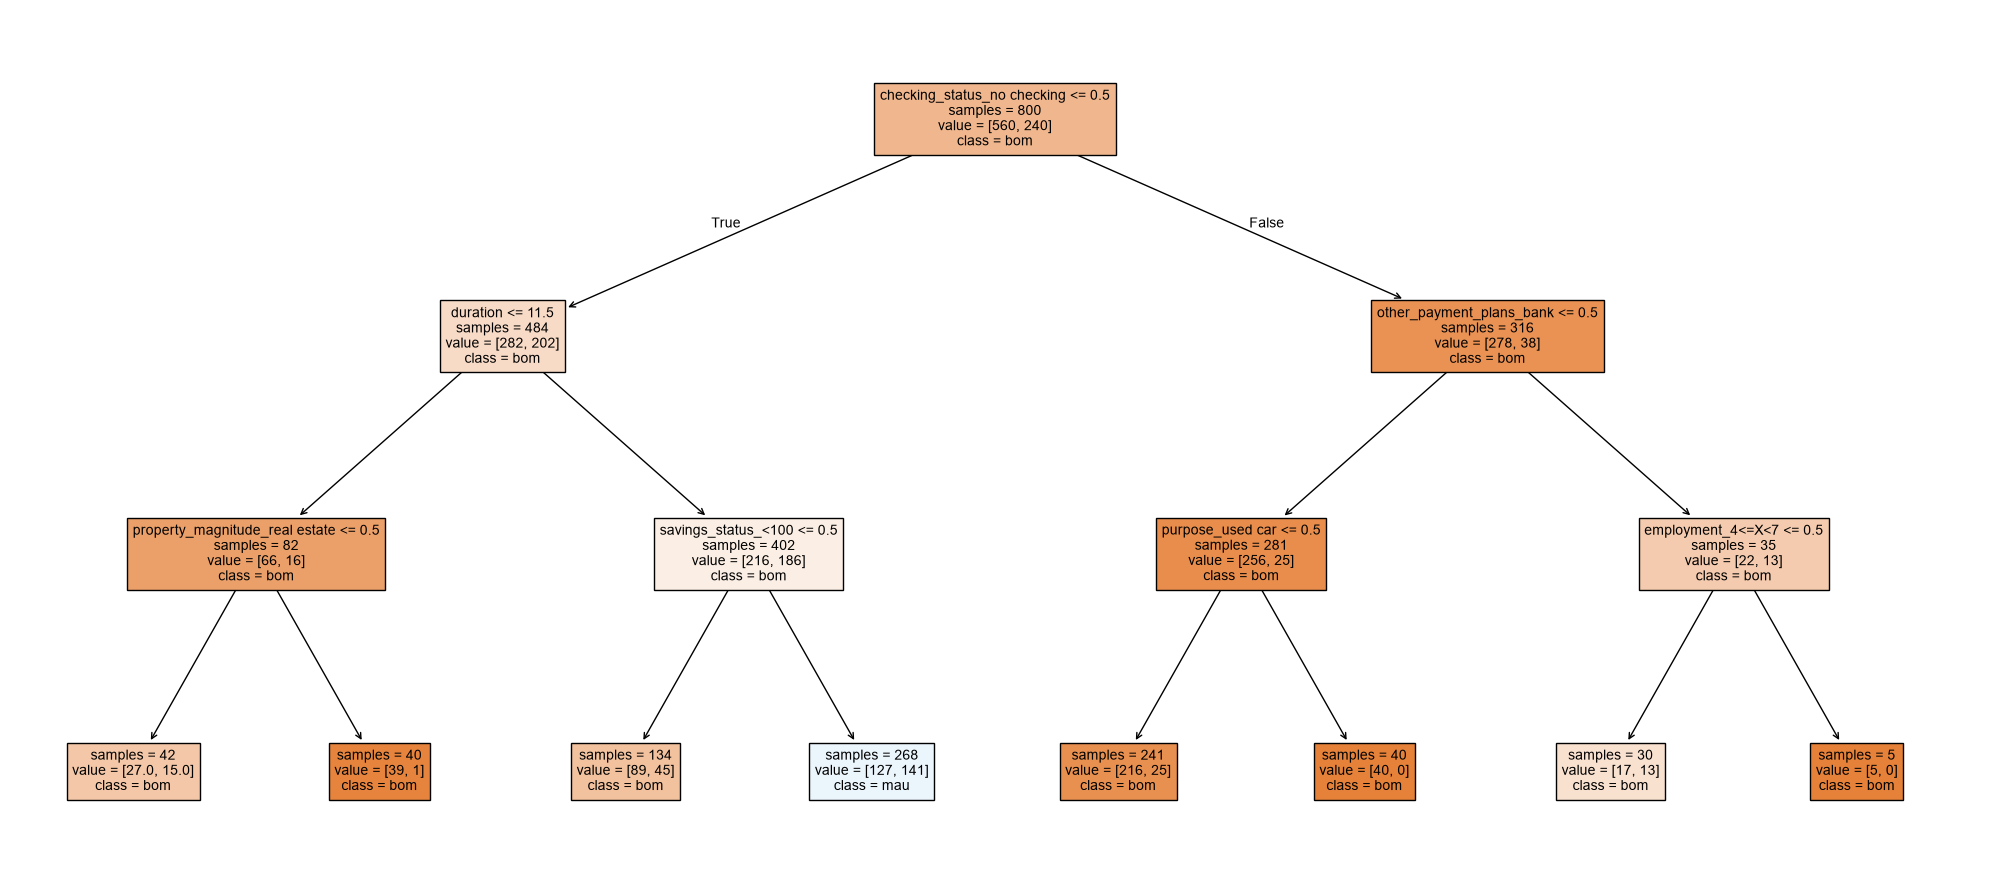

In [19]:
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(
        model,
        feature_names=list(X_enc.columns),
        class_names=["bom", "mau"],
        filled=True,
        impurity=False,
        fontsize=10,
        ax=ax,
    )
fig.tight_layout()
plt.savefig("figuras/arvore_decisao.png", dpi=150, bbox_inches="tight")
plt.show()

Podemos também visualizar a estrutura em forma de árvore textual utilizando a função `export_text`:

In [20]:
print(
    export_text(
        model,
        feature_names=list(X_enc.columns),
        class_names=["bom", "mau"]
    )
)

|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- property_magnitude_real estate <= 0.50
|   |   |   |--- class: bom
|   |   |--- property_magnitude_real estate >  0.50
|   |   |   |--- class: bom
|   |--- duration >  11.50
|   |   |--- savings_status_<100 <= 0.50
|   |   |   |--- class: bom
|   |   |--- savings_status_<100 >  0.50
|   |   |   |--- class: mau
|--- checking_status_no checking >  0.50
|   |--- other_payment_plans_bank <= 0.50
|   |   |--- purpose_used car <= 0.50
|   |   |   |--- class: bom
|   |   |--- purpose_used car >  0.50
|   |   |   |--- class: bom
|   |--- other_payment_plans_bank >  0.50
|   |   |--- employment_4<=X<7 <= 0.50
|   |   |   |--- class: bom
|   |   |--- employment_4<=X<7 >  0.50
|   |   |   |--- class: bom



A importância de cada atributo é a redução total de impureza trazida pelos *splits* que usam esse atributo. Como o *one-hot encoding* divide cada atributo categórico em várias colunas, também somamos a importância das colunas de um mesmo atributo original:

In [21]:
importancias = pd.Series(model.feature_importances_, index=X_enc.columns).sort_values(ascending=False)
print("Colunas mais importantes:")
print(importancias.head(10).round(4))

origem = {c: c for c in cols_num}
for atributo, categorias in zip(cols_cat, oh.categories_):
    for cat in categorias:
        origem[f"{atributo}_{cat}"] = atributo

imp_atributo = importancias.groupby(importancias.index.map(origem)).sum().sort_values(ascending=False)
print("\nImportância por atributo original:")
print(imp_atributo.round(4))

Colunas mais importantes:
checking_status_no checking       0.5153
duration                          0.1277
other_payment_plans_bank          0.1022
property_magnitude_real estate    0.0992
savings_status_<100               0.0778
purpose_used car                  0.0475
employment_4<=X<7                 0.0302
age                               0.0000
num_dependents                    0.0000
checking_status_<0                0.0000
dtype: float64

Importância por atributo original:
checking_status           0.5153
duration                  0.1277
other_payment_plans       0.1022
property_magnitude        0.0992
savings_status            0.0778
purpose                   0.0475
employment                0.0302
age                       0.0000
credit_history            0.0000
credit_amount             0.0000
existing_credits          0.0000
foreign_worker            0.0000
num_dependents            0.0000
job                       0.0000
installment_commitment    0.0000
housing           

Agora vamos encontrar a folha com o **maior número de amostras de mau pagador** (no treino) e o caminho da raiz até ela. Nas colunas *one-hot*, o teste `<= 0.50` significa "não pertence à categoria" e `> 0.50` significa "pertence":

In [22]:
folhas = model.apply(X_train)
contagem_folhas = pd.DataFrame({"folha": folhas, "mau": y_train.values}).groupby("folha")["mau"].agg(["sum", "count"])
contagem_folhas.columns = ["mau", "total"]

folha_alvo = contagem_folhas["mau"].idxmax()
n_mau, n_total = contagem_folhas.loc[folha_alvo]
print(f"Folha {folha_alvo}: {n_mau} maus e {n_total - n_mau} bons ({100 * n_mau / n_total:.1f}% de maus)")

arv = model.tree_

def caminho_ate(no_alvo, no=0, trilha=()):
    if no == no_alvo:
        return list(trilha)
    if arv.children_left[no] == -1:     # chegou em outra folha
        return None
    nome, lim = X_enc.columns[arv.feature[no]], arv.threshold[no]
    return (caminho_ate(no_alvo, arv.children_left[no], trilha + ((nome, "<=", lim),))
            or caminho_ate(no_alvo, arv.children_right[no], trilha + ((nome, ">", lim),)))

print("\nRegra (da raiz até essa folha):")
for nome, op, lim in caminho_ate(folha_alvo):
    print(f"  {nome} {op} {lim:.2f}")

Folha 7: 141 maus e 127 bons (52.6% de maus)

Regra (da raiz até essa folha):
  checking_status_no checking <= 0.50
  duration > 11.50
  savings_status_<100 > 0.50


## 7. Tarefa 6: Avaliação do Modelo

Calculando a acurácia e as métricas por classe no conjunto de teste:

In [23]:
y_pred = model.predict(X_test)
print(f"Acurácia (teste):  {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Bom (0)", "Mau (1)"], zero_division=0))

Acurácia (teste):  0.6850

              precision    recall  f1-score   support

     Bom (0)       0.80      0.74      0.77       140
     Mau (1)       0.48      0.57      0.52        60

    accuracy                           0.69       200
   macro avg       0.64      0.65      0.64       200
weighted avg       0.70      0.69      0.69       200



Bem como a matriz de confusão:

Matriz de confusão (teste):
          prev bom  prev mau
real bom       103        37
real mau        26        34


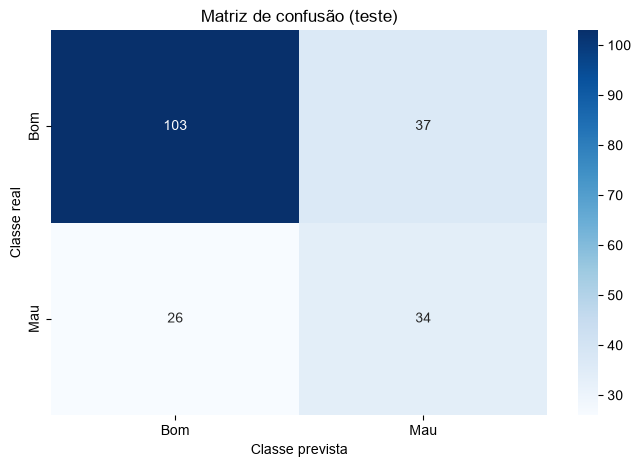

In [24]:
cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusão (teste):")
print(pd.DataFrame(cm, index=["real bom", "real mau"], columns=["prev bom", "prev mau"]))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Bom", "Mau"], yticklabels=["Bom", "Mau"])
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão (teste)")
plt.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

O erro mais grave nesta aplicação é **aprovar um mau pagador** (falso negativo da classe "mau"), que gera prejuízo direto. Um ajuste para reduzi-lo é tratar o desbalanceamento **no treinamento**. Como visto na aula de pré-processamento, o SMOTE cria amostras sintéticas da classe minoritária, e deve ser aplicado **apenas no conjunto de treino**. Também testamos a alternativa de ponderar as classes (`class_weight="balanced"`), que dá mais peso aos erros na classe minoritária. É apenas uma demonstração do efeito: o critério e a profundidade continuam os escolhidos por validação cruzada, sem usar o teste para ajustar nada.

In [25]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(k_neighbors=5, random_state=42)
X_bal, y_bal = sm.fit_resample(X_train, y_train)   # SOMENTE no treino

print("Treino antes  :", pd.Series(y_train).value_counts().to_dict())
print("Treino depois :", pd.Series(y_bal).value_counts().to_dict())

Treino antes  : {0: 560, 1: 240}
Treino depois : {1: 560, 0: 560}


In [26]:
params = dict(criterion=criterio_otimo, max_depth=profundidade_otima, random_state=42)
ajustes = {
    "original": DecisionTreeClassifier(**params).fit(X_train, y_train),
    "SMOTE": DecisionTreeClassifier(**params).fit(X_bal, y_bal),
    "class_weight": DecisionTreeClassifier(**params, class_weight="balanced").fit(X_train, y_train),
}

for nome, m in ajustes.items():
    p = m.predict(X_test)
    VN, FP, FN, VP = confusion_matrix(y_test, p).ravel()
    print(f"{nome:12s} | Acurácia: {accuracy_score(y_test, p):.4f} | "
          f"Recall (mau): {recall_score(y_test, p):.4f} | maus aprovados (FN): {FN} | bons recusados (FP): {FP}")

original     | Acurácia: 0.6850 | Recall (mau): 0.5667 | maus aprovados (FN): 26 | bons recusados (FP): 37
SMOTE        | Acurácia: 0.6550 | Recall (mau): 0.6500 | maus aprovados (FN): 21 | bons recusados (FP): 48
class_weight | Acurácia: 0.6050 | Recall (mau): 0.8667 | maus aprovados (FN): 8 | bons recusados (FP): 71
